# 02 - Late-delivery model

**Question.** When a customer places an order, can we tell which orders are most likely to arrive *after* the delivery date they were promised?

This notebook walks through the model end to end, with the charts: the data, how the model is tested, how well it ranks orders, what it relies on, what I tried that did not help, and why August 2018 broke it. All the logic lives in tested modules under `src/ml/`; the notebook calls them and draws the results. The written summary is [docs/ml/MODEL_CARD.md](../docs/ml/MODEL_CARD.md).

**To run it:** build the warehouse first (`uv run python src/transformation/build_warehouse.py`), then run all cells. The whole notebook takes about two minutes.

**What to expect.** The model is a moderate ranker, not a crystal ball: flagging the riskiest 10% of orders catches late deliveries about 2.8 times better than chance on average. Several attempts to improve it did not work, and the notebook shows why.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.metrics import average_precision_score, precision_recall_curve

# The repository root is the folder that holds pyproject.toml, wherever this notebook is started from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src" / "ml"))
import explain_late_delivery as eld  # noqa: E402
import late_delivery_baseline as ldb  # noqa: E402

WAREHOUSE = ROOT / "warehouse.duckdb"
if not WAREHOUSE.exists():
    raise FileNotFoundError("warehouse.duckdb not found. Run: uv run python src/transformation/build_warehouse.py")

# One restrained palette: blue is the model / normal case, orange is lateness / the thing to look at, grey is context.
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b9b8b1"
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3de"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "figure.dpi": 100,
})

con = duckdb.connect(str(WAREHOUSE), read_only=True)
df = ldb.load(con)          # one row per delivered order: features known at purchase, plus the label
con.close()
FEATURES = ldb.NUMERIC_V1 + ldb.CATEGORICAL
print(f"{len(df):,} delivered orders, {df['is_late'].mean():.1%} arrived late")
print(f"{len(ldb.NUMERIC_V1)} numeric + {len(ldb.CATEGORICAL)} categorical features")

96,282 delivered orders, 8.1% arrived late
16 numeric + 3 categorical features


## 1. The data

The label is `is_late`: the order arrived after the estimated delivery date shown at checkout. About 8% of delivered orders are late, but that rate swings a lot from month to month, which is the main difficulty in this problem.

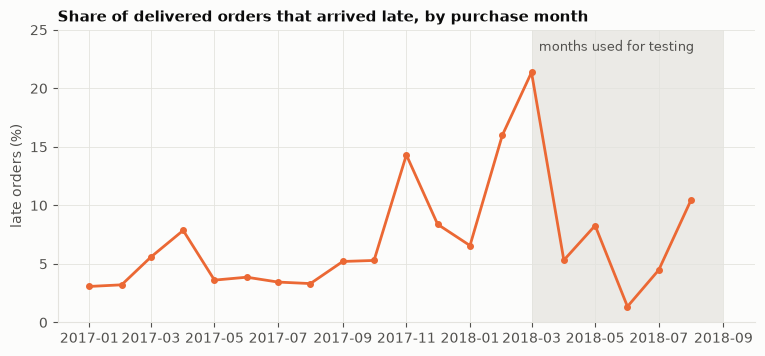

In [2]:
m = df.groupby("month")["is_late"].agg(orders="size", late="mean")
m = m[m["orders"] >= 500]
x = m.index.to_timestamp()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(x, 100 * m["late"], color=ORANGE, marker="o", markersize=4)
ax.axvspan(pd.Timestamp("2018-03-01"), pd.Timestamp("2018-09-01"), color=GRID, alpha=0.7, linewidth=0)
ax.set_ylim(0, 25)
ax.text(pd.Timestamp("2018-03-08"), 23.2, "months used for testing", color=INK_2, fontsize=9)
ax.set_title("Share of delivered orders that arrived late, by purchase month")
ax.set_ylabel("late orders (%)")
plt.show()

The late rate sits near 3% to 8% for most of 2017, then spikes (14% in November 2017, 21% in March 2018) and drops to 1.4% in June 2018. **A model has to rank orders correctly in all of these very different months.**

The promised delivery window is the other thing to look at. Here is the late rate for orders grouped by how long the customer was promised:

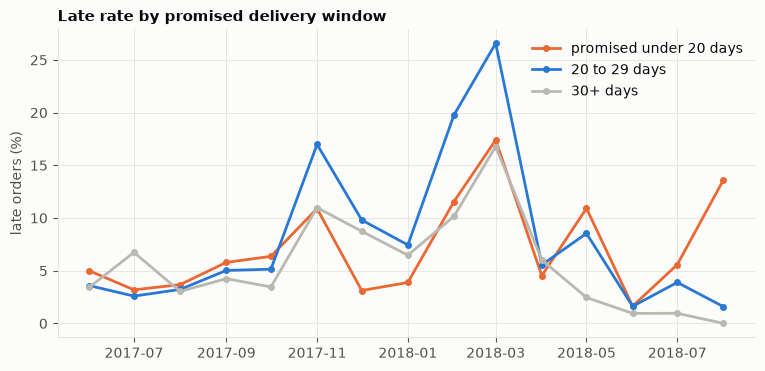

In [3]:
d = df.copy()
d["promise"] = pd.cut(d["promised_days"], [0, 20, 30, 1000], right=False, labels=["promised under 20 days", "20 to 29 days", "30+ days"])
t = d.groupby(["month", "promise"], observed=True)["is_late"].agg(["mean", "size"]).reset_index()
t = t[t["size"] >= 100]
pivot = 100 * t.pivot(index="month", columns="promise", values="mean")
pivot = pivot.loc[pd.Period("2017-06"):]

fig, ax = plt.subplots(figsize=(9, 4))
for column, colour in zip(pivot.columns, [ORANGE, BLUE, GREY]):
    ax.plot(pivot.index.to_timestamp(), pivot[column], color=colour, marker="o", markersize=4, label=column)
ax.set_title("Late rate by promised delivery window")
ax.set_ylabel("late orders (%)")
ax.legend(frameon=False)
plt.show()

The three groups mostly move together, driven by the month (the spikes in November 2017 and March 2018 hit every group, the middle group hardest). **In August 2018 they split apart: orders promised in under 20 days are late about 14% of the time, while the 30+ day promises are almost never late.** Which promise length is "risky" is not constant over time. Keep this chart in mind; it explains why the model struggles in the last test month.

## 2. How the model is tested

Orders are tested **in time order**, never shuffled: for each test month, the model trains only on orders whose delivery was already known before that month began, then scores that month's orders. This mimics real use, where you can only learn from the past.

The blue bar is what the model could learn from; the orange bar is the month it is scored on.

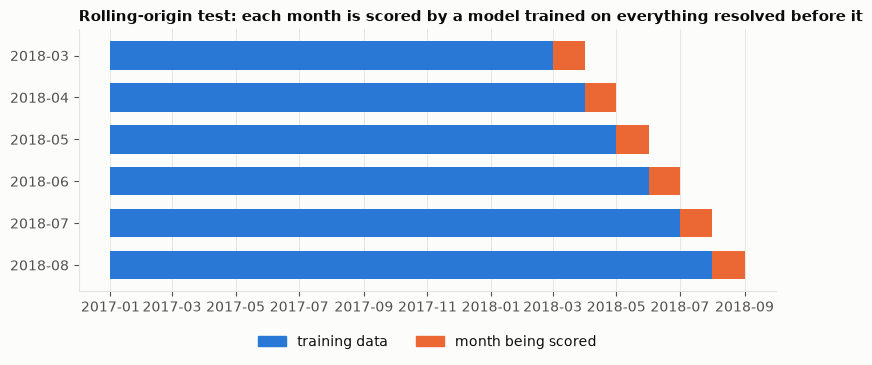

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for i, month in enumerate(ldb.TEST_MONTHS):
    start, end = month.start_time, month.end_time
    left = mdates.date2num(ldb.TRAIN_START)
    ax.broken_barh([(left, mdates.date2num(start) - left)], (i - 0.34, 0.68), facecolors=BLUE)
    ax.broken_barh([(mdates.date2num(start), mdates.date2num(end) - mdates.date2num(start))], (i - 0.34, 0.68), facecolors=ORANGE)
ax.xaxis_date()
ax.set_yticks(range(len(ldb.TEST_MONTHS)))
ax.set_yticklabels([str(m) for m in ldb.TEST_MONTHS])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Rolling-origin test: each month is scored by a model trained on everything resolved before it")
ax.legend(handles=[Patch(color=BLUE, label="training data"), Patch(color=ORANGE, label="month being scored")], frameon=False,
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.show()

## 3. Training and scoring

The model is a **logistic regression** on 19 features known at purchase: the promised window, basket size and weight, the customer's and seller's state, the distance between them, weekday and hour, payment details, and the seller's late rate over earlier resolved orders. Nothing that is only known after delivery is used (see [LEAKAGE_ANALYSIS.md](../docs/ml/LEAKAGE_ANALYSIS.md)).

One model is trained per test month. The cell keeps the scores so the next charts can use them.

In [5]:
store = {}
rows = []
for month in ldb.TEST_MONTHS:
    start = month.start_time
    train = df[(df["purchase_ts"] >= ldb.TRAIN_START) & (df["delivered_customer_ts"] < start)]
    test = df[df["month"] == month]
    model = ldb.make_models(ldb.NUMERIC_V1, "v1")["logistic_regression_v1"].fit(train[FEATURES], train["is_late"])
    p = model.predict_proba(test[FEATURES])[:, 1]
    y = test["is_late"].to_numpy()
    store[str(month)] = {"y": y, "p": p, "model": model, "test": test, "train_rate": train["is_late"].mean()}
    rows.append({"month": str(month), "train_orders": len(train), **ldb.evaluate(y, p)})

summary = pd.DataFrame(rows).set_index("month")
summary[["train_orders", "n", "base_rate", "pr_auc", "roc_auc", "brier", "precision_at_top", "recall_at_top"]].round(3)

,train_orders,n,base_rate,pr_auc,roc_auc,brier,precision_at_top,recall_at_top
month,,,,,,,,
2018-03,53358,7003,0.214,0.393,0.692,0.178,0.506,0.237
2018-04,60182,6791,0.053,0.180,0.788,0.048,0.208,0.391
2018-05,68031,6719,0.083,0.212,0.731,0.072,0.232,0.281
2018-06,75115,6050,0.014,0.061,0.770,0.017,0.050,0.366
2018-07,81901,6119,0.045,0.129,0.663,0.053,0.124,0.277
2018-08,87701,6306,0.105,0.127,0.601,0.098,0.125,0.120


How to read it: `base_rate` is the share of late orders (what random guessing would achieve). `pr_auc` is how well the ranking concentrates late orders at the top (random = the base rate). `precision_at_top` and `recall_at_top` describe the riskiest 10% of orders: the share of those that are late, and the share of all late orders they catch.

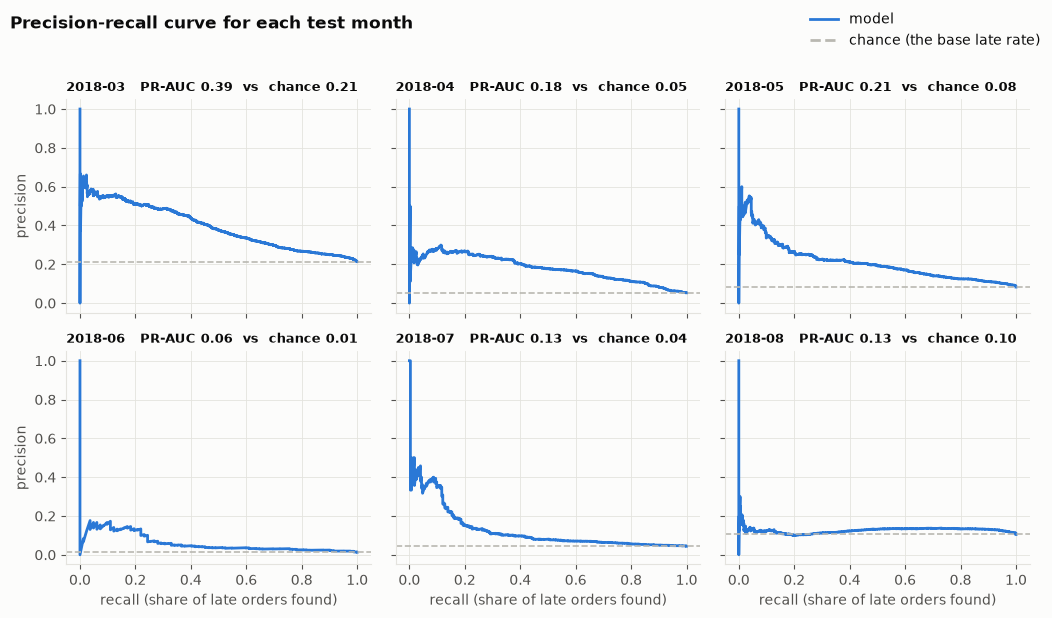

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.2), sharex=True, sharey=True)
for ax, (month, s) in zip(axes.flat, store.items()):
    precision, recall, _ = precision_recall_curve(s["y"], s["p"])
    ax.plot(recall, precision, color=BLUE)
    ax.axhline(s["y"].mean(), color=GREY, linestyle="--", linewidth=1.2)
    ax.set_title(f"{month}   PR-AUC {average_precision_score(s['y'], s['p']):.2f}  vs  chance {s['y'].mean():.2f}", fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("recall (share of late orders found)")
for ax in axes[:, 0]:
    ax.set_ylabel("precision")
fig.legend(handles=[Line2D([0], [0], color=BLUE, label="model"), Line2D([0], [0], color=GREY, linestyle="--", label="chance (the base late rate)")],
           loc="upper right", frameon=False)
fig.suptitle("Precision-recall curve for each test month", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

A curve well above the dashed line means the model ranks late orders ahead of on-time ones. It does in five months. In **August** the curve hugs the line: the model barely beats chance there.

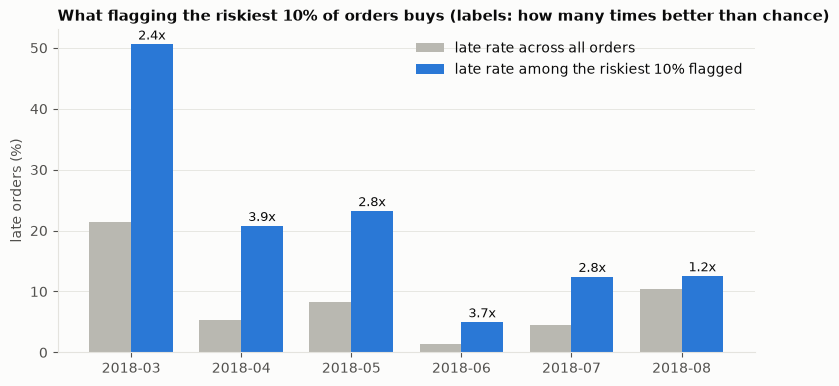

mean lift over the six months: 2.8x


In [7]:
x = np.arange(len(summary))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(x - w / 2, 100 * summary["base_rate"], w, color=GREY, label="late rate across all orders")
ax.bar(x + w / 2, 100 * summary["precision_at_top"], w, color=BLUE, label="late rate among the riskiest 10% flagged")
for i, (base, top) in enumerate(zip(summary["base_rate"], summary["precision_at_top"])):
    ax.text(i + w / 2, 100 * top + 0.8, f"{top / base:.1f}x", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(summary.index)
ax.set_ylabel("late orders (%)")
ax.grid(axis="x", visible=False)
ax.set_title("What flagging the riskiest 10% of orders buys (labels: how many times better than chance)")
ax.legend(frameon=False, loc="upper right")
plt.show()
print(f"mean lift over the six months: {(summary['precision_at_top'] / summary['base_rate']).mean():.1f}x")

This is the practical result. Flagging the riskiest 10% of orders finds late deliveries **2.4 to 3.9 times more often than chance in five of the six months**, and only 1.2 times in August 2018.

### Are the predicted probabilities right?

A ranker can be useful even when its probabilities are off. Here is how far off they are:

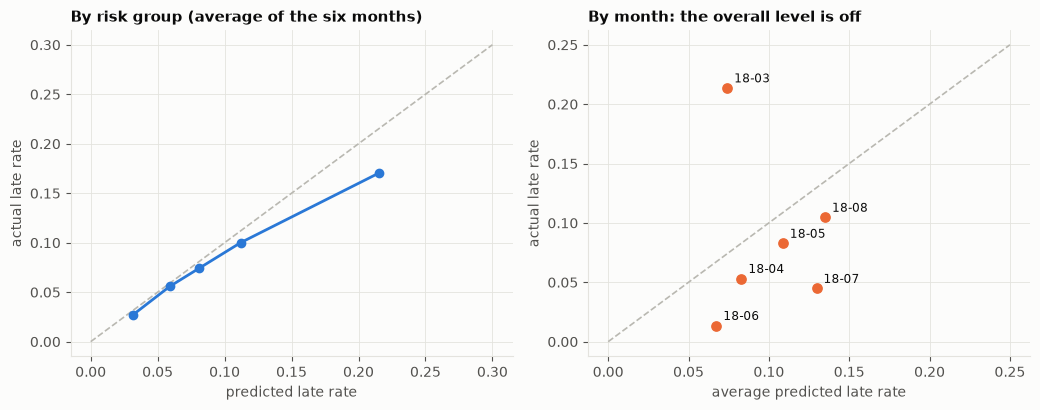

mean absolute monthly error in the predicted level: 0.061


In [8]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 4.2))

# Left: within each month, split orders into five equal groups by predicted risk and compare predicted with actual.
parts = []
for month, s in store.items():
    bucket = pd.qcut(pd.Series(s["p"]).rank(method="first"), 5, labels=False)
    parts.append(pd.DataFrame({"b": bucket, "pred": s["p"], "actual": s["y"]}).groupby("b").mean())
cal = pd.concat(parts).groupby(level=0).mean()
a.plot([0, 0.3], [0, 0.3], color=GREY, linestyle="--", linewidth=1.2)
a.plot(cal["pred"], cal["actual"], color=BLUE, marker="o")
a.set_xlabel("predicted late rate")
a.set_ylabel("actual late rate")
a.set_title("By risk group (average of the six months)")

# Right: the average prediction for each month against that month's actual late rate.
levels = pd.DataFrame({m: {"pred": s["p"].mean(), "actual": s["y"].mean()} for m, s in store.items()}).T
b.plot([0, 0.25], [0, 0.25], color=GREY, linestyle="--", linewidth=1.2)
b.scatter(levels["pred"], levels["actual"], color=ORANGE, s=45, zorder=3)
for month, r in levels.iterrows():
    b.annotate(month[2:], (r["pred"], r["actual"]), xytext=(5, 4), textcoords="offset points", fontsize=8.5, color=INK)
b.set_xlabel("average predicted late rate")
b.set_ylabel("actual late rate")
b.set_title("By month: the overall level is off")
plt.tight_layout()
plt.show()
print(f"mean absolute monthly error in the predicted level: {(levels['pred'] - levels['actual']).abs().mean():.3f}")

**Left:** inside a month, the ranking is sensible (higher predicted risk means a higher actual rate), though the riskiest group is over-predicted. **Right:** the *level* is wrong by month: the model predicted about 7% in March 2018 when the real rate was 21%. The late rate swings between months in a way the past does not predict (I tested recalibrating on recent data; it made things worse, see [RECALIBRATION_AND_WINDOW.md](../docs/ml/RECALIBRATION_AND_WINDOW.md)).

**So: use the model by rank, flagging a share of orders, not by quoting probabilities.**

## 4. What does the model rely on?

Permutation importance: shuffle one group of related columns in a test month and see how much the ranking quality (PR-AUC) drops. A bigger drop means the model leans on that group more. Each grey dot is one test month; the bar is their average. This cell takes about a minute.

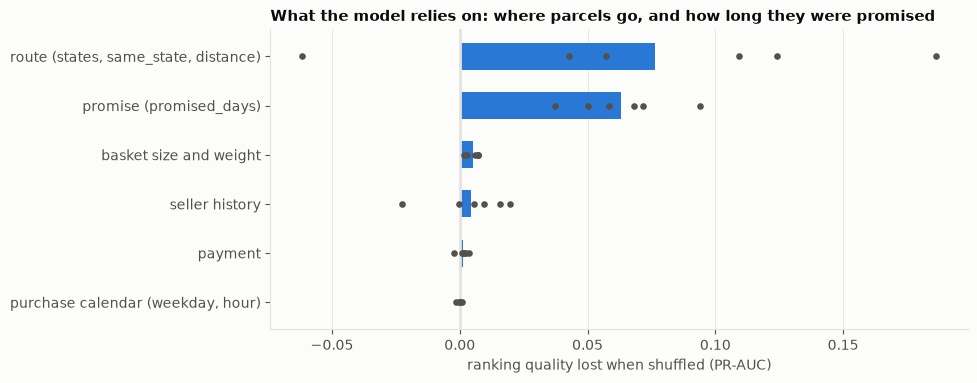

In [9]:
rng = np.random.default_rng(0)
drops = {g: [] for g in eld.GROUPS}
for month, s in store.items():
    test, model = s["test"], s["model"]
    base = average_precision_score(test["is_late"], model.predict_proba(test[FEATURES])[:, 1])
    for group, columns in eld.GROUPS.items():
        drops[group].append(eld.permutation_drop(model, test, columns, base, rng))
imp = pd.DataFrame(drops, index=list(store)).T
imp["mean"] = imp.mean(axis=1)
imp = imp.sort_values("mean")

fig, ax = plt.subplots(figsize=(9, 3.9))
ax.barh(imp.index, imp["mean"], color=BLUE, height=0.55)
for y, (_, row) in enumerate(imp.iterrows()):
    ax.scatter(row.drop("mean"), [y] * (len(row) - 1), color=INK_2, s=14, zorder=3)
ax.axvline(0, color=GRID)
ax.set_xlabel("ranking quality lost when shuffled (PR-AUC)")
ax.set_title("What the model relies on: where parcels go, and how long they were promised")
ax.grid(axis="y", visible=False)
plt.show()

Two groups do almost all the work: **the route** (customer state, seller state, same-state flag and distance) and **the promise** (`promised_days`). Basket size, seller history, payment and time of day add almost nothing. Notice that one grey dot for the route group is *negative* (August): shuffling the route information actually improved the ranking that month, another sign that the geographic pattern learned earlier did not hold in August.

### Which way do the features push?

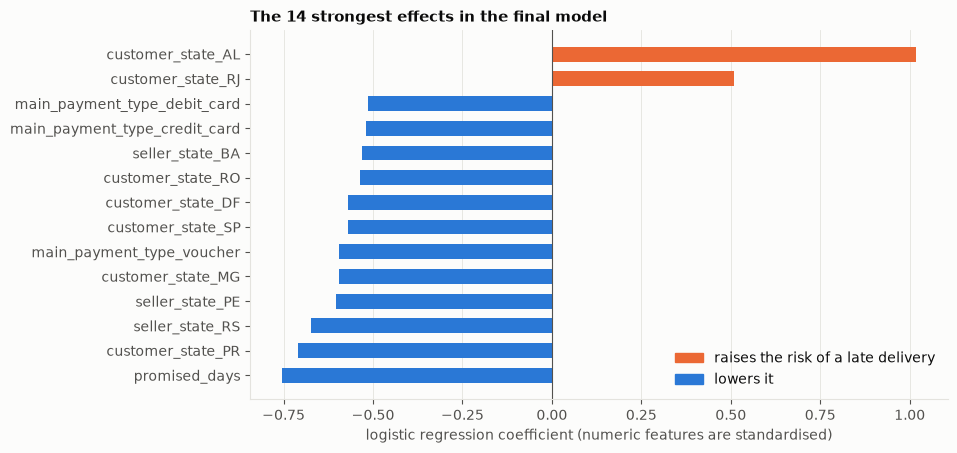

In [10]:
last = ldb.TEST_MONTHS[-1].start_time
train = df[(df["purchase_ts"] >= ldb.TRAIN_START) & (df["delivered_customer_ts"] < last)]
final = ldb.make_models(ldb.NUMERIC_V1, "v1")["logistic_regression_v1"].fit(train[FEATURES], train["is_late"])
names = [n.split("__", 1)[1] for n in final[:-1].get_feature_names_out()]
coef = pd.Series(final[-1].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(14).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(top.index, top.values, color=[ORANGE if v > 0 else BLUE for v in top.values], height=0.6)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set_xlabel("logistic regression coefficient (numeric features are standardised)")
ax.set_title("The 14 strongest effects in the final model")
ax.legend(handles=[Patch(color=ORANGE, label="raises the risk of a late delivery"), Patch(color=BLUE, label="lowers it")], frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

A longer promise (`promised_days`) is the strongest numeric effect and lowers the risk: customers promised more time are less often late. Destination matters: some states carry a high risk (Alagoas, Rio de Janeiro) and others a low one (Paraná, Minas Gerais, São Paulo). State and payment-type columns are one-hot with no reference category, so their absolute sizes are shared with the model's intercept: compare states with states, not with payment types.

## 5. What I tried that did not help

Several ideas were tested against the same six months, plus gradient boosting as an alternative model. The plain model ("v1") was never beaten. The feature sets compared here are:

| set | adds |
|---|---|
| **v1** | the features above (the reference) |
| v2 | late-rate history for the route and the product category |
| v3 | v2 plus the system-wide late rate over the previous 28 days |
| v5 | v1 plus delivery-time *slack* (promised days minus how long deliveries on that route have been taking) |

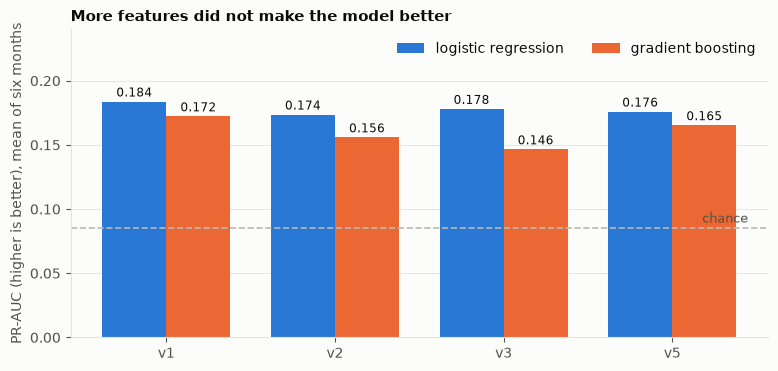

In [11]:
import json

macro = pd.DataFrame(json.loads((ROOT / "reports" / "late_delivery_metrics.json").read_text(encoding="utf-8"))["macro_average"]).T
sets = ["v1", "v2", "v3", "v5"]
logit = [macro.loc[f"logistic_regression_{s}", "pr_auc"] for s in sets]
boost = [macro.loc[f"gradient_boosting_{s}", "pr_auc"] for s in sets]
base = macro.loc["constant_train_rate", "pr_auc"]

x = np.arange(len(sets))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w / 2, logit, w, color=BLUE, label="logistic regression")
ax.bar(x + w / 2, boost, w, color=ORANGE, label="gradient boosting")
ax.axhline(base, color=GREY, linestyle="--", linewidth=1.2)
ax.text(len(sets) - 0.55, base + 0.004, "chance", color=INK_2, fontsize=9, ha="right")
for xi, v in zip(x - w / 2, logit):
    ax.text(xi, v + 0.004, f"{v:.3f}", ha="center", fontsize=8.5)
for xi, v in zip(x + w / 2, boost):
    ax.text(xi, v + 0.004, f"{v:.3f}", ha="center", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(sets)
ax.set_ylabel("PR-AUC (higher is better), mean of six months")
ax.set_title("More features did not make the model better")
ax.set_ylim(0, 0.24)
ax.legend(frameon=False, loc="upper right", ncol=2)
ax.grid(axis="x", visible=False)
plt.show()

Every added feature set leaves the logistic model no better and the boosted model worse. I tested *why*, in [DRIFT_ANALYSIS.md](../docs/ml/DRIFT_ANALYSIS.md): the trailing late rate and category history track the regime of the training period, which does not carry forward; route history is stable but repeats what the state and distance columns already provide; and delivery slack added nothing. Recalibration and tuning the training window were also tested and rejected (DD-11, DD-12).

## 6. Why August 2018 breaks the model

For each month, how well does a single feature rank that month's orders on its own? An AUC of 0.5 means no skill, and below 0.5 means the feature points the wrong way. (This comes from [drift_analysis.py](../src/ml/drift_analysis.py).)

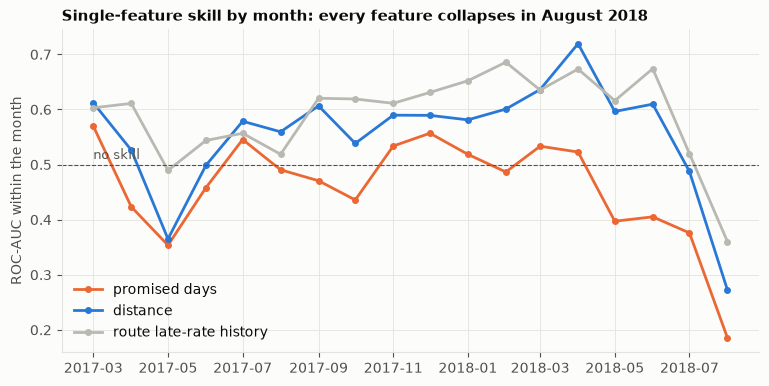

In [12]:
drift = json.loads((ROOT / "reports" / "drift_metrics.json").read_text(encoding="utf-8"))["E1"]["by_month"]
auc = pd.DataFrame(drift).set_index("month")
auc.index = pd.PeriodIndex(auc.index, freq="M").to_timestamp()

fig, ax = plt.subplots(figsize=(9, 4.2))
for column, colour, label in [("promised_days", ORANGE, "promised days"), ("distance_km", BLUE, "distance"), ("route_rate", GREY, "route late-rate history")]:
    ax.plot(auc.index, auc[column], color=colour, marker="o", markersize=4, label=label)
ax.axhline(0.5, color=INK_2, linewidth=0.8, linestyle="--")
ax.text(auc.index[0], 0.51, "no skill", color=INK_2, fontsize=9)
ax.set_ylabel("ROC-AUC within the month")
ax.set_title("Single-feature skill by month: every feature collapses in August 2018")
ax.legend(frameon=False, loc="lower left")
plt.show()

In August 2018 the promised window and the distance both fall well below 0.5: the promise had been shortened sharply (75% of that month's orders were promised in under 20 days), and short promises, not long routes, were the ones that came late. The model learned from earlier months that a long promise on a long route is safe; in August the rule no longer held.

## Takeaways

- **The model ranks orders moderately well.** Flagging the riskiest 10% finds late deliveries about 2.8 times better than chance on average (1.2 times in the worst month).
- **Use it by rank, not by probability.** The monthly late rate cannot be predicted from the past, so the level of its probabilities is unreliable.
- **It rests on the route and the promise.** Everything else adds little.
- **It is fragile to policy change.** A sharp change in how delivery dates are promised breaks it, so a monitor on the distribution of promised days is worth having.
- **More features did not help**, and the notebook shows the evidence rather than just the conclusion.

**Limits.** Six test months, one market, data ending in 2018, and a model tested without tuning. Details and caveats are in [MODEL_CARD.md](../docs/ml/MODEL_CARD.md).